In [1]:
# kagglehub 설치
# %pip install kagglehub

# 전자상거래 고객 이탈 분석 및 예측 데이터 다운로드
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ankitverma2010/ecommerce-customer-churn-analysis-and-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\pc-999\.cache\kagglehub\datasets\ankitverma2010\ecommerce-customer-churn-analysis-and-prediction\versions\1


In [3]:
import pandas as pd
import os

# 엑셀 파일을 DataFrame으로 불러오기
df = pd.read_excel(
    os.path.join(path, "E Commerce Dataset.xlsx"),
    sheet_name="E Comm"
)

# 데이터 확인
#df.info()
#df.head(10)

# Churn(0: 이탈하지 않은 고객, 1: 이탈한 고객)
df['Churn'].value_counts()

Churn
0    4682
1     948
Name: count, dtype: int64

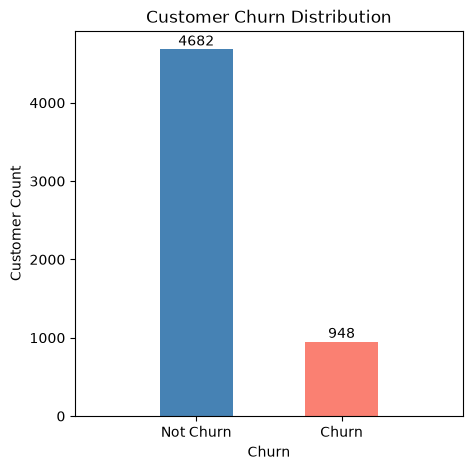

In [19]:
import matplotlib.pyplot as plt

# 이탈 여부별 고객 수
churn_counts = df['Churn'].value_counts().sort_index()

# 그래프 크기 설정
plt.figure(figsize=(5, 5))

# 막대 위치 지정
x = [0, 0.6]

plt.bar(
    x,
    churn_counts.values,
    width=0.3,
    color=['steelblue', 'salmon']
)

# X축 이름 지정
plt.xticks(x, ['Not Churn', 'Churn'])

# X축 범위 조절
plt.xlim(-0.5, 1.1)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Customer Count')

# 고객 수 표시
for pos, count in zip(x, churn_counts.values):
    plt.text(pos, count + 50, str(count), ha='center')

plt.show()

In [26]:
# 컬럼별 결측치 개수 확인
df.isnull().sum()

# 컬럼별 결측치 비율 (%)
(df.isnull().mean() * 100).round(2)

# 결측치가 존재하는 컬럼 추출
null_cols = df.columns[df.isnull().any()]

# 평균과 중앙값 비교
df[null_cols].agg(['mean', 'median']).round(2)

,Tenure,WarehouseToHome,HourSpendOnApp,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder
mean,10.19,15.64,2.93,15.71,1.75,3.01,4.54
median,9.00,14.00,3.00,15.00,1.00,2.00,3.00
